<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px" />

# Quiz 2

This notebook contains 5 parts. You are to fill in this quiz with your answers, taking special care to follow the directions _exactly_.

To **submit** your quiz, hit **turn in** in the google classroom assignment.

### Quiz Information:
- This is an "open book" quiz - you may use any resources! This includes Jupyter notebooks, Google, StackOverflow, and your notes. ANY RESOURCE YOU USE MUST BE CITED (comment your code with links, which lesson you got the inspiration from, etc.) and failure to cite resources you use will be considered plagiarism.
- You may NOT work with anyone else on this quiz (your classmates, your instructor, etc.).
- You will have one hour to take this quiz.

## Part 1: Getting the data
The linked provided dataset (`concrete.csv`) consists of various amounts of different components used to create concrete and the concrete's [compressive strength](https://www.aboutcivil.org/compressive-strength-of-concrete.html). A data dictionary for this dataset can be found below:

Variable Name | Description | Units
--- | --- | ---
Cement | component 1 | kg (number of kilograms of the component in a cubic meter of concrete)
Blast Furnace Slag | component 2 | kg (in a cubic meter of concrete)
Fly Ash | component 3 | kg (in a cubic meter of concrete)
Water | component 4 | kg (in a cubic meter of concrete)
Superplasticizer | component 5 | kg (in a cubic meter of concrete)
Coarse Aggregate | component 6 | kg (in a cubic meter of concrete)
Fine Aggregate | component 7 | kg (in a cubic meter of concrete)
Age | Age of concrete | Day (1~365)
Concrete compressive strength | Target variable | [MPa](https://www.sensorsone.com/mpa-megapascal-pressure-unit/)


**Read in the data and display the first 5 rows.**

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

df = pd.read_csv('./data/concrete.csv')#, index_col=0)

In [31]:
# First 5
df.head()

,Unnamed: 0,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,2,332.5,142.5,0.0,228.0,NaN,932.0,594.0,270,40.27
3,3,332.5,142.5,0.0,228.0,NaN,932.0,594.0,365,41.05
4,4,198.6,132.4,0.0,192.0,NaN,978.4,825.5,360,44.30


## Part 2: Data Cleaning

There are a few issues with this dataset. To help you identify and fix these issues, you are told:
- The `Unnamed: 0` column should not be a part of this dataset.
- Any null values in this dataset are clerical errors. They should all be 0's.
- All columns in this dataset should be numeric.

**Please clean up the dataset.**

In [32]:
df.head()

,Unnamed: 0,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,2,332.5,142.5,0.0,228.0,NaN,932.0,594.0,270,40.27
3,3,332.5,142.5,0.0,228.0,NaN,932.0,594.0,365,41.05
4,4,198.6,132.4,0.0,192.0,NaN,978.4,825.5,360,44.30


In [33]:
# Drop unnamed 0, two ways
df.drop(columns=["Unnamed: 0"], inplace=True)

In [34]:
# Repl nulls with 0s
df.fillna(value=0, inplace=True)

In [35]:
df.isna().sum()

Cement                           0
Blast Furnace Slag               0
Fly Ash                          0
Water                            0
Superplasticizer                 0
Coarse Aggregate                 0
Fine Aggregate                   0
Age                              0
Concrete compressive strength    0
dtype: int64

In [36]:
# Numeric
df['Age'].unique()

array(['28', '270', '365', '360', '90', '180', '3', '7', '56', '91', '14',
       '100', "'28'", '120', '1'], dtype=object)

In [37]:
df['Age'] = pd.to_numeric(df['Age'], errors='raise')

# note: errors = coerce will add back nulls

ValueError: Unable to parse string "'28'" at position 434

In [38]:
df['Age'] = df['Age'].str.replace("'", "")

In [39]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

In [40]:
df.isna().sum()

Cement                           0
Blast Furnace Slag               0
Fly Ash                          0
Water                            0
Superplasticizer                 0
Coarse Aggregate                 0
Fine Aggregate                   0
Age                              0
Concrete compressive strength    0
dtype: int64

## Part 3: EDA

You are asked to give the following to the hiring manager:
- Descriptive statistics of the Water column
- A scatterplot of Coarse Aggregate compared to Fine Aggregate colored purple with a title and axis labels

**Please display these.**

In [41]:
# What's the fastest way?
df['Water'].describe()

count    1030.000000
mean      181.567282
std        21.354219
min       121.800000
25%       164.900000
50%       185.000000
75%       192.000000
max       247.000000
Name: Water, dtype: float64

In [42]:
df.columns

Index(['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer',
       'Coarse Aggregate', 'Fine Aggregate', 'Age',
       'Concrete compressive strength'],
      dtype='object')

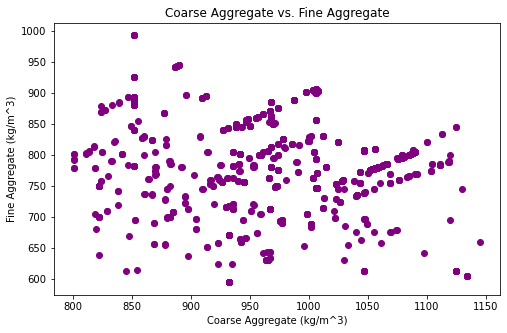

In [43]:
# Scatterplot
plt.figure(figsize=(8, 5))
plt.scatter(df['Coarse Aggregate'], df['Fine Aggregate'], color='purple')
plt.xlabel('Coarse Aggregate (kg/m^3)')
plt.ylabel('Fine Aggregate (kg/m^3)')
plt.title('Coarse Aggregate vs. Fine Aggregate');

## Part 4: Modeling

**Fit a linear regression model to predict the concrete compressive strength. Use *all* columns (other than your target) in your model to predict the concrete compressive strength.**
* Please use a random state of `2020` when splitting your data
* Use 80% of the dataset for training and the other 20% for testing
* Print out and interpret the testing R<sup>2</sup>.

In [53]:
# X and Y
X = df.drop(columns=['Concrete compressive strength'])
y = df['Concrete compressive strength']


In [54]:
# TTS
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 2020, train_size = .8)

In [55]:
# Instantiate and fit
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [56]:
# Training R2
lr.score(X_train, y_train)

0.6187699710545507

In [57]:
# Testing R2
lr.score(X_test, y_test)

0.5979187032701263

Interpret R2: 59.8% of the variability in concrete compressive strength can be explained by its relationship with the other features in our model.

## Part 5: Interpretation

The firm is especially interested in learning more about the effects of [superplasticizer](https://en.wikipedia.org/wiki/Superplasticizer).

**They ask you what effect the Superplasticizer has on the concrete compressive strength. How would you respond? Be as specific as possible.**

*Hint: you may want to check out the [data dictionary](https://archive.ics.uci.edu/ml/datasets/Concrete+Compressive+Strength).*

In [58]:
lr

LinearRegression()

In [59]:
# Check coefs
pd.Series(lr.coef_, X.columns)

Cement                0.116718
Blast Furnace Slag    0.099552
Fly Ash               0.086012
Water                -0.174673
Superplasticizer      0.258219
Coarse Aggregate      0.010311
Fine Aggregate        0.014275
Age                   0.111217
dtype: float64

Interpret: Holding all else constant, per 1 kg increase of superplasticizer per cubic meter, we can expect a 0.25 increase in MPa compressive strength.

In [60]:
import statsmodels.api as sm

In [61]:
# X and Y
X = sm.add_constant(X)
ols = sm.OLS(y, X).fit()
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                  OLS Regression Results                                 
=========================================================================================
Dep. Variable:     Concrete compressive strength   R-squared:                       0.616
Model:                                       OLS   Adj. R-squared:                  0.613
Method:                            Least Squares   F-statistic:                     204.3
Date:                           Fri, 14 Jun 2024   Prob (F-statistic):          6.29e-206
Time:                                   07:43:27   Log-Likelihood:                -3869.0
No. Observations:                           1030   AIC:                             7756.
Df Residuals:                               1021   BIC:                             7800.
Df Model:                                      8                                         
Covariance Type:                       nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                -23.3312     26.586     -0.878      0.380     -75.500      28.837
Cement                 0.1198      0.008     14.113      0.000       0.103       0.136
Blast Furnace Slag     0.1039      0.010     10.247      0.000       0.084       0.124
Fly Ash                0.0879      0.013      6.988      0.000       0.063       0.113
Water                 -0.1499      0.040     -3.731      0.000      -0.229      -0.071
Superplasticizer       0.2922      0.093      3.128      0.002       0.109       0.476
Coarse Aggregate       0.0181      0.009      1.926      0.054      -0.000       0.037
Fine Aggregate         0.0202      0.011      1.887      0.059      -0.001       0.041
Age                    0.1142      0.005     21.046      0.000       0.104       0.125
==============================================================================
Omnibus:                        5.378   Durbin-Watson:                   1.282
Prob(Omnibus):                  0.068   Jarque-Bera (JB):                5.304
Skew:                          -0.174   Prob(JB):                       0.0705
Kurtosis:                       3.045   Cond. No.                     1.06e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.06e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

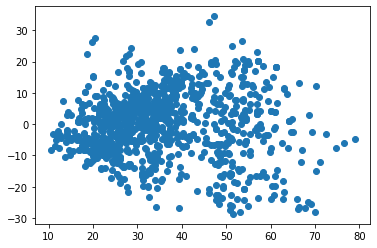

In [64]:
preds = ols.predict(X)
resids = y - preds
plt.scatter(preds, resids);